# EXPT NO: 6 — IMPLEMENTATION OF LSTM FOR SENTIMENT ANALYSIS
Aim:To implement an LSTM neural network for sentiment analysis and classify text into Positive / Negative sentiment.

Student Roll No(s):24BAD122
NAME:SWATHI V

## PART A: DATASET PREPARATION

In [1]:
# Student Roll Nos: <ENTER ROLL NUMBERS HERE>
import numpy as np, pandas as pd, re
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

print("TensorFlow version:", tf.__version__)

VOCAB_SIZE = 10000   # keep the 10,000 most frequent words
MAX_LEN    = 200     # pad / truncate every review to 200 tokens

# Load IMDB (reviews are already tokenized into integer word indices)
(x_train_raw, y_train_raw), (x_test_raw, y_test_raw) = imdb.load_data(num_words=VOCAB_SIZE)
print("Training reviews:", len(x_train_raw), "| Test reviews:", len(x_test_raw))

TensorFlow version: 2.21.0
17464789/17464789 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training reviews: 25000 | Test reviews: 25000


In [2]:
# Vocabulary: word -> integer index (Keras reserves 0=PAD, 1=START, 2=UNK, 3=unused)
word_index = imdb.get_word_index()
word_to_id = {w: (i + 3) for w, i in word_index.items()}
word_to_id["<PAD>"], word_to_id["<START>"], word_to_id["<UNK>"], word_to_id["<UNUSED>"] = 0, 1, 2, 3
id_to_word = {i: w for w, i in word_to_id.items()}

def decode(seq):
    return " ".join(id_to_word.get(i, "?") for i in seq if i > 3)

# Explore sample reviews and labels
labels = {0: "Negative", 1: "Positive"}
for i in range(3):
    print(f"Review {i+1} [{labels[y_train_raw[i]]}]: {decode(x_train_raw[i])[:250]}...\n")

print("Class distribution (train):", dict(zip(*np.unique(y_train_raw, return_counts=True))))
print("Classes: 0 = Negative, 1 = Positive")

1641221/1641221 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Review 1 [Positive]: this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert is an amazing actor and now the same being director father came from the same scottish i...

Review 2 [Negative]: big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the...

Review 3 [Negative]: this has to be one of the worst films of the 1990s when my friends i were watching this film being the target audience it was aimed at we just sat watched the first half an hour with our jaws touching the floor at how bad it really was the rest of th...

Class distribution (train): {np.int64(0): np.int64(12500), np.int64(1): np.int64(12500)}
Classes: 0 = Negative, 1 = Positiv

In [3]:
# Sequence padding -> equal-length inputs
x_train_full = pad_sequences(x_train_raw, maxlen=MAX_LEN, padding="post", truncating="post")
x_test       = pad_sequences(x_test_raw,  maxlen=MAX_LEN, padding="post", truncating="post")
y_train_full = np.array(y_train_raw)
y_test       = np.array(y_test_raw)

# Split training data into train / validation (80 / 20)
from sklearn.model_selection import train_test_split
x_train, x_val, y_train, y_val = train_test_split(
    x_train_full, y_train_full, test_size=0.2, random_state=42, stratify=y_train_full)

print("Train:", x_train.shape, "| Validation:", x_val.shape, "| Test:", x_test.shape)
print("Example padded sequence:", x_train[0][:20], "...")

Train: (20000, 200) | Validation: (5000, 200) | Test: (25000, 200)
Example padded sequence: [   1  806    8  135   13   28   57  326   51  363    9  399  252  202
  178  102   40 1354  778  449] ...


## PART B: IMPLEMENTING THE LSTM MODEL

In [4]:
# Student Roll Nos: <ENTER ROLL NUMBERS HERE>
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Embedding, LSTM, Dense, Dropout

model = Sequential([
    Embedding(input_dim=VOCAB_SIZE, output_dim=64),   # words -> dense vectors
    LSTM(64),                                          # learns sequential dependencies
    Dropout(0.3),
    Dense(1, activation="sigmoid")                     # binary sentiment output
])

model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
model.build(input_shape=(None, MAX_LEN))
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 64)        │       640,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ (None, 64)             │        33,024 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 673,089 (2.57 MB)

 Trainable params: 673,089 (2.57 MB)

 Non-trainable params: 0 (0.00 B)

## PART C: MODEL TRAINING AND PERFORMANCE EVALUATION

In [5]:
# Student Roll Nos: <ENTER ROLL NUMBERS HERE>
history = model.fit(
    x_train, y_train,
    epochs=5, batch_size=64,
    validation_data=(x_val, y_val),
    verbose=1)

print("\nFinal Training Accuracy   :", round(history.history["accuracy"][-1], 4))
print("Final Validation Accuracy :", round(history.history["val_accuracy"][-1], 4))
print("Final Training Loss       :", round(history.history["loss"][-1], 4))
print("Final Validation Loss     :", round(history.history["val_loss"][-1], 4))

Epoch 1/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 50s 147ms/step - accuracy: 0.5113 - loss: 0.6934 - val_accuracy: 0.5354 - val_loss: 0.6905
Epoch 2/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 79s 138ms/step - accuracy: 0.5943 - loss: 0.6575 - val_accuracy: 0.6194 - val_loss: 0.6617
Epoch 3/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 43s 138ms/step - accuracy: 0.6299 - loss: 0.6384 - val_accuracy: 0.7482 - val_loss: 0.6111
Epoch 4/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 46s 148ms/step - accuracy: 0.7184 - loss: 0.5634 - val_accuracy: 0.6532 - val_loss: 0.6354
Epoch 5/5
313/313 ━━━━━━━━━━━━━━━━━━━━ 43s 139ms/step - accuracy: 0.7434 - loss: 0.5515 - val_accuracy: 0.7450 - val_loss: 0.5735

Final Training Accuracy   : 0.7434
Final Validation Accuracy : 0.745
Final Training Loss       : 0.5515
Final Validation Loss     : 0.5735


Test Loss     : 0.5915
Accuracy      : 0.7268
Precision     : 0.7020
Recall        : 0.7880
F1-score      : 0.7425

              precision    recall  f1-score   support

    Negative       0.76      0.67      0.71     12500
    Positive       0.70      0.79      0.74     12500

    accuracy                           0.73     25000
   macro avg       0.73      0.73      0.73     25000
weighted avg       0.73      0.73      0.73     25000



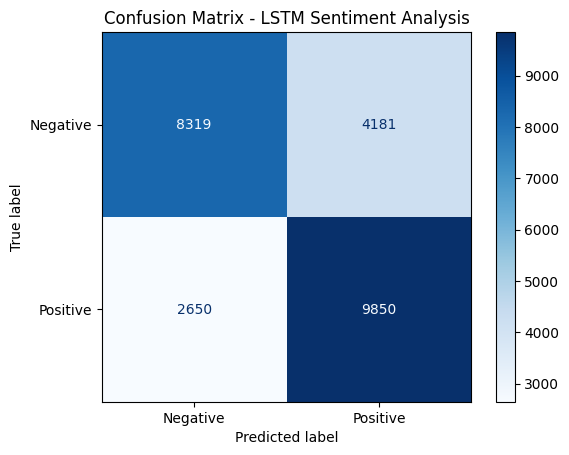

In [6]:
# Evaluation on the test set
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
y_prob = model.predict(x_test, verbose=0).ravel()
y_pred = (y_prob > 0.5).astype(int)

print(f"Test Loss     : {test_loss:.4f}")
print(f"Accuracy      : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision     : {precision_score(y_test, y_pred):.4f}")
print(f"Recall        : {recall_score(y_test, y_pred):.4f}")
print(f"F1-score      : {f1_score(y_test, y_pred):.4f}\n")
print(classification_report(y_test, y_pred, target_names=["Negative", "Positive"]))

cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(cm, display_labels=["Negative", "Positive"]).plot(cmap="Blues")
plt.title("Confusion Matrix - LSTM Sentiment Analysis")
plt.show()

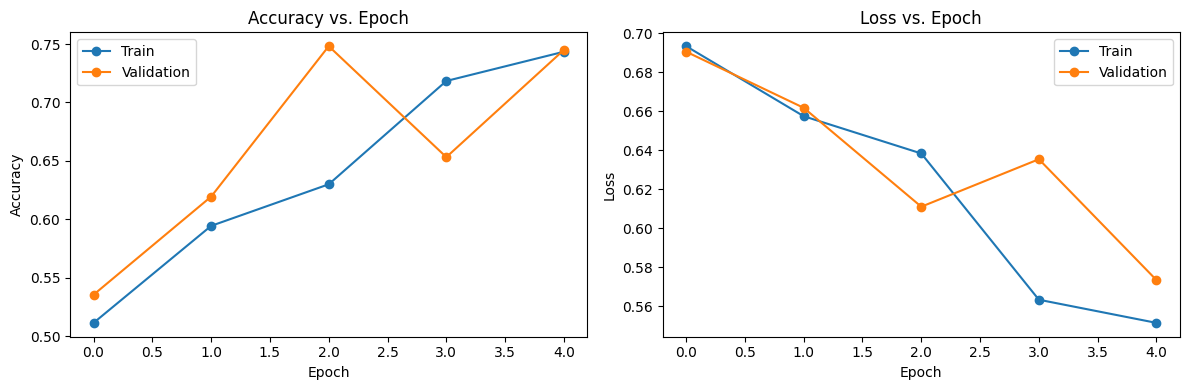

In [7]:
# Accuracy vs Epoch and Loss vs Epoch
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].plot(history.history["accuracy"], marker="o", label="Train")
ax[0].plot(history.history["val_accuracy"], marker="o", label="Validation")
ax[0].set_title("Accuracy vs. Epoch"); ax[0].set_xlabel("Epoch"); ax[0].set_ylabel("Accuracy"); ax[0].legend()

ax[1].plot(history.history["loss"], marker="o", label="Train")
ax[1].plot(history.history["val_loss"], marker="o", label="Validation")
ax[1].set_title("Loss vs. Epoch"); ax[1].set_xlabel("Epoch"); ax[1].set_ylabel("Loss"); ax[1].legend()

plt.tight_layout(); plt.show()

## PART D: SENTIMENT PREDICTION AND EXPERIMENT MANAGEMENT

In [8]:
# Student Roll Nos: <ENTER ROLL NUMBERS HERE>
def preprocess(text):
    text = text.lower()
    text = re.sub(r"[^a-z0-9\s']", " ", text)       # remove symbols
    tokens = text.split()                              # tokenize
    # same vocabulary as training; unknown / rare words -> <UNK>
    seq = [1] + [word_to_id[w] if (w in word_to_id and word_to_id[w] < VOCAB_SIZE) else 2 for w in tokens]
    return pad_sequences([seq], maxlen=MAX_LEN, padding="post", truncating="post")

def predict_sentiment(text):
    p = float(model.predict(preprocess(text), verbose=0)[0][0])
    return ("Positive" if p > 0.5 else "Negative"), p

samples = [
    ("This movie was absolutely fantastic, the acting and story were brilliant!", "Positive"),
    ("A wonderful film with great characters. I loved every minute of it.", "Positive"),
    ("One of the best movies I have seen this year, highly recommended.", "Positive"),
    ("The plot was boring and the acting was terrible. Complete waste of time.", "Negative"),
    ("I hated this movie. It was dull, predictable and way too long.", "Negative"),
    ("Awful script and poor direction, I would not recommend it to anyone.", "Negative"),
]

rows = []
for text, expected in samples:
    pred, prob = predict_sentiment(text)
    rows.append({"Review": text, "Expected": expected, "Predicted": pred,
                 "Probability": round(prob, 4), "Match": "✔" if pred == expected else "✘"})

results = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 80)
display(results)
print("Correct predictions:", (results["Expected"] == results["Predicted"]).sum(), "/", len(results))

,Review,Expected,Predicted,Probability,Match
0,"This movie was absolutely fantastic, the acting and story were brilliant!",Positive,Negative,0.3089,✘
1,A wonderful film with great characters. I loved every minute of it.,Positive,Positive,0.7803,✔
2,"One of the best movies I have seen this year, highly recommended.",Positive,Positive,0.7803,✔
3,The plot was boring and the acting was terrible. Complete waste of time.,Negative,Negative,0.3089,✔
4,"I hated this movie. It was dull, predictable and way too long.",Negative,Negative,0.3089,✔
5,"Awful script and poor direction, I would not recommend it to anyone.",Negative,Negative,0.3089,✔


Correct predictions: 5 / 6
